# nnHALO, end to end

This notebook is the whole pipeline of **nnHALO**, the submitted model, from the raw competition images to the
submission file and its evaluation. The implementation lives in `src/filament_seg/`; each cell calls it.

**weights → (optional) training → input channels → two networks → candidates → selector → submission rows → evaluation**

| section | what it does | default |
|---|---|---|
| 1. Weights | joins the stored weight parts and checks every file against `weights/MANIFEST.sha256` | runs |
| 2. Training | the full training recipe (`TRAIN = True`, ~65 GPU-h for 10 fold trainings), or a short smoke run that proves the training commands work (`SMOKE_TRAIN`) | smoke only |
| 3. Prediction | the 180 test observations from the raw JPEGs: channels, both networks, the selector, the CSV, and its check against the submitted file | runs |
| 4. One observation | the intermediate images of one test observation | runs |
| 5. Evaluation | the paper's Table 1 on the out-of-fold training observations, against a held-out annotator, with its reproduction checks | runs |
| 6. Runtime | measured time of every stage of this run | runs |

- **Inputs:** **your** competition download (`$FILAMENT_KAGGLE_ROOT`; the data is not redistributed) and the files of
  this repository: the two networks in `weights/fast/` (parts of at most 90 MiB because GitHub blocks larger files),
  the selector in `weights/selector/FAST_bag.pkl`, and `eval_bundle/` for the evaluation.
- **Environments:** this kernel `requirements/notebook.txt`; the steps run with the interpreters named by
  `FILAMENT_PY_CPU` (channels, selector, evaluation) and `FILAMENT_PY_NNUNET` (nnU-Net), see the README.
- **Same result as the submitted file?** Everything after the networks is deterministic, but GPU inference is not
  bit-exact from run to run, so one or two borderline objects can differ. Section 3 applies the repository's
  reproduction rule (`configs/FAST.json`, `reproduction_tolerance`) and prints its verdict.

In [1]:
import csv, json, os, pickle, subprocess, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools import mask as mask_utils

ROOT = Path.cwd() if (Path.cwd() / "src" / "filament_seg").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from filament_seg import candidates, config, filament_paths as fp, render, training, weights
from filament_seg.gpu import pipeline
from filament_seg.prep import channels, prepare
from filament_seg.submission import rle

TRAIN = False          # True: retrain both networks (5 folds each) and refit the selector, ~65 GPU-h
SMOKE_TRAIN = True     # run the short training smoke test (10 images, 1 epoch): proves the training path runs
CASE_INDEX = 6         # the test observation followed in section 4 (see its rule there)

cfg = config.load("FAST")
nn_py = pipeline.interpreter("nnunet")
probe = subprocess.run([nn_py, "-c", "import nnunetv2, torch; print(torch.cuda.is_available())"],
                       capture_output=True, text=True)
assert probe.returncode == 0, ("the nnU-Net interpreter cannot import nnunetv2 and torch: set FILAMENT_PY_NNUNET to the "
                               "environment of requirements/nnunet-gpu.lock.txt (README, Environments)")
DEVICE = os.environ.get("FILAMENT_DEVICE") or ("cuda" if probe.stdout.strip() == "True" else "cpu")
TIMES = {}
print("device:", DEVICE, "| TRAIN =", TRAIN, "| SMOKE_TRAIN =", SMOKE_TRAIN)

def show(ax, a, title, **kw):
    ax.imshow(a[::4, ::4], **kw); ax.set_title(title, fontsize=9); ax.axis("off")

device: cuda | TRAIN = False | SMOKE_TRAIN = True


## 1. Weights

`weights.assemble` joins the stored parts of each network into `$FILAMENT_WEIGHTS` and checks every file against
`weights/MANIFEST.sha256`; a file with a wrong hash is deleted and the call fails. The files are named
`checkpoint_final.pth` because that is nnU-Net's name for a trained model; they hold the network weights only (the
optimizer state was removed).

In [2]:
t0 = time.time()
placed = weights.assemble()
for rel in placed:
    if rel.endswith("checkpoint_final.pth"):
        print(f"{(fp.WEIGHTS / rel).stat().st_size / 1e6:7.1f} MB  {rel}")
print(len(placed), "files in place and verified")
TIMES["weights"] = time.time() - t0

  236.8 MB  nnUNet_results/Dataset007_FilamentVessel/nnUNetTrainer_250epochs__nnUNetPlans__2d/fold_0/checkpoint_final.pth
  236.8 MB  nnUNet_results/Dataset036_LimbDarkBarbClass/nnUNetTrainer_250epochs__nnUNetPlans__2d/fold_0/checkpoint_final.pth
8 files in place and verified


## 2. Training (optional)

`filament_seg.training` holds the recipe that produced the shipped weights (`docs/TRAINING.md`), as steps:
channels and labels of the 707 training images from the competition download, then for each network (Dataset007,
five channels; Dataset036, six channels) nnU-Net planning and preprocessing, the five-fold splits, and five trainings
of 250 epochs; then the out-of-fold maps the selector learns from, and the selector fit. Models are written to
`$FILAMENT_WORK/nnunet_env/nnUNet_results`, never over the shipped weights. Training is not bit-reproducible on a
GPU, so a retrain gives slightly different weights and submission.

The splits are fixed by a rule (sorted case ids, fold k = every fifth case from k) that reproduces the shipped splits
exactly (`tests/test_training.py`). With `TRAIN = False` the recipe is listed, not run, and sections 3–5 use the
shipped weights. The smoke run uses the same commands on 10 training images for 1 epoch; it proves the path runs and
says nothing about accuracy.

In [3]:
TRAIN_ROOT = fp.WORK / "train"          # the training run root: its own data, models and selector bag
steps = training.full_recipe(TRAIN_ROOT)
print(f"full recipe: {len(steps)} steps")
for s in steps:
    print(f"  [{s.kind:6s}] {s.name}" + (f"   ({s.note.replace(str(fp.WORK), '$FILAMENT_WORK')})" if s.note else ""))
if TRAIN:
    t0 = time.time()
    assert training.run(steps, TRAIN_ROOT, quiet=True) == 0, "a training step failed: see $FILAMENT_WORK/train/logs"
    TIMES["training (full)"] = time.time() - t0
    os.environ["FILAMENT_WEIGHTS_NNUNET"] = str(training.results_dir(TRAIN_ROOT))   # sections 3-4 use the retrained models
    print("TRAIN = True: sections 3-4 use the retrained networks and selector bag")
else:
    print("TRAIN = False: the shipped weights are used (set TRAIN = True to retrain, ~65 GPU-h).")
if SMOKE_TRAIN:
    smoke_root = fp.WORK / "train_smoke"
    t0 = time.time()
    rc = training.run(training.smoke_recipe(smoke_root), smoke_root, quiet=True)
    TIMES["training smoke test"] = time.time() - t0
    log = smoke_root / "logs" / "train_Dataset007_FilamentVessel_fold_0.log"
    last = [l for l in log.read_text().splitlines() if "Mean Validation Dice" in l] if log.exists() else []
    print("smoke training:", "passed" if rc == 0 else f"FAILED (rc {rc})", "|", last[-1].split(": ", 1)[-1] if last else "")
    assert rc == 0

full recipe: 25 steps
  [cpu   ] channels   (707 training images, several in parallel)
  [cpu   ] labels   (union label (D007), barb-class label (D036), from the competition COCO)
  [cpu   ] selector tables
  [nnunet] plan + preprocess Dataset007_FilamentVessel
  [cpu   ] splits Dataset007_FilamentVessel
  [nnunet] train Dataset007_FilamentVessel fold 0   (~6.5 h on the reference laptop GPU)
  [nnunet] train Dataset007_FilamentVessel fold 1   (~6.5 h on the reference laptop GPU)
  [nnunet] train Dataset007_FilamentVessel fold 2   (~6.5 h on the reference laptop GPU)
  [nnunet] train Dataset007_FilamentVessel fold 3   (~6.5 h on the reference laptop GPU)
  [nnunet] train Dataset007_FilamentVessel fold 4   (~6.5 h on the reference laptop GPU)
  [nnunet] plan + preprocess Dataset036_LimbDarkBarbClass
  [cpu   ] splits Dataset036_LimbDarkBarbClass
  [nnunet] train Dataset036_LimbDarkBarbClass fold 0   (~6.5 h on the reference laptop GPU)
  [nnunet] train Dataset036_LimbDarkBarbClass fold 1

  labels                                       running


  numTraining Dataset007_FilamentVessel        running


  plan + preprocess Dataset007_FilamentVessel  running


  splits Dataset007_FilamentVessel             running


  train Dataset007_FilamentVessel fold 0       running


smoke training: passed | Mean Validation Dice:  0.5150484740978527


## 3. Prediction: the 180 test observations

`pipeline.run(["FAST"])` is what `scripts/predict.py --slot FAST --from-images` runs:

1. the input channels of the 180 test images (`prep.channels`, several images in parallel);
2. the five-channel nnU-Net (Dataset007, fold 0), whose foreground probability gives the candidates;
3. the six-channel nnU-Net (Dataset036, fold 0), whose mask only feeds the selector;
4. the selector stage: candidates, features, the bag's scores, the kept masks, the CSV
   (`submissions/out/FAST.csv`), `verify_submission`, and the comparison with the submitted `submissions/FAST.csv`.

The selector's second member mask, P, needs no network: it is the Dataset007 probability map at p ≥ 0.5. Every step
is resumable; each step's log is in `$FILAMENT_WORK/logs/`.

In [4]:
import contextlib, io
buf = io.StringIO()
with contextlib.redirect_stdout(buf):                 # the step list is printed as JSON lines with absolute paths
    rc = pipeline.run(["FAST"], device=DEVICE, log_dir=fp.WORK / "logs",
                      bag_dir=str(training.bag_dir(TRAIN_ROOT)) if TRAIN else None)
for line in buf.getvalue().splitlines():
    if line.startswith("{"):
        j = json.loads(line)
        if "seconds" in j:
            TIMES[j["step"]] = j["seconds"]
            print(f"{j['step']:20s} ran in {j['seconds']:7.1f} s")
        elif j.get("complete"):
            print(f"{j['step']:20s} already on disk")
res = [json.loads(l) for l in (fp.WORK / "logs" / "selector_FAST.log").read_text().splitlines() if l.startswith("{")][-1]
if TRAIN:      # retrained networks: the comparison with the submitted file is information, not a pass/fail
    assert res["verify_rc"] == 0, "the submission failed verify_submission"
else:
    assert rc == 0, [l for l in buf.getvalue().splitlines() if "failed" in l] or "a step failed; see $FILAMENT_WORK/logs"
t = res["tolerance"]
print(f"submission: {res['rows']} rows, verify_submission rc {res['verify_rc']}")
print(f"vs the submitted file: {t['reference_rows']} rows; images whose object count differs: {len(t['images_count_differs'])}; "
      f"pooled Dice over the count-matched images {t['pooled_dice_count_matched']:.6f}")
print("within the reproduction tolerance:", res["within_tolerance"])

channels             ran in   240.1 s
base_D007_f0         ran in   373.6 s
bin_D036_f0          ran in   403.8 s
selector_FAST        ran in   128.4 s
submission: 1186 rows, verify_submission rc 0
vs the submitted file: 1185 rows; images whose object count differs: 1; pooled Dice over the count-matched images 0.999987
within the reproduction tolerance: True


## 4. One observation through the pipeline

Test observation 6 (`filamentTs_0006`, `20110429120534Ch`), chosen so that the selector is seen deleting something.
The rule, applied in sorted case order to the released selector's decisions in a fresh-clone run: *the first test
observation in which the selector deletes a candidate of at least 1,000 px that scores at least 0.05 below the cut*
(the margin keeps GPU run-to-run noise from flipping the decision). Set `CASE_INDEX` to follow another observation;
everything below reads the outputs of section 3.

filamentTs_0006 20110429120534Ch


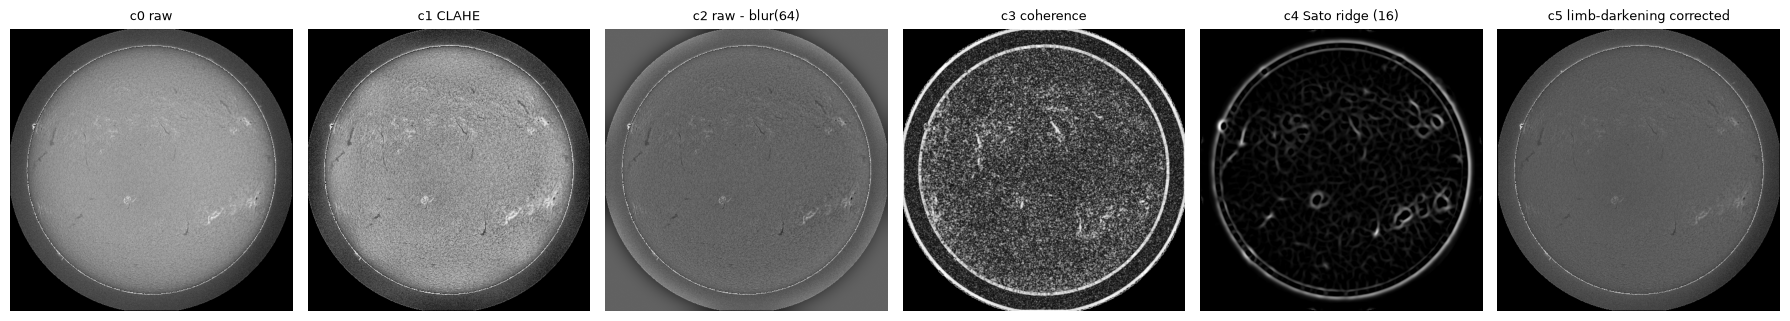

In [5]:
test_cases = json.load(open(fp.CONFIGS / "case_mapping_full.json"))["test"]       # case id -> image file
case = sorted(test_cases)[CASE_INDEX]
image_id = os.path.splitext(test_cases[case])[0]
raw = prepare.raw_u8(prepare.kaggle_image(fp.KAGGLE_ROOT, "test", image_id + ".jpeg"))
ch = channels.all_channels(raw)["Dataset036_LimbDarkBarbClass"]
names = ["c0 raw", "c1 CLAHE", "c2 raw - blur(64)", "c3 coherence", "c4 Sato ridge (16)", "c5 limb-darkening corrected"]
print(case, image_id)
fig, axs = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, a, n in zip(axs, ch, names):
    show(ax, a, n, cmap="gray")
plt.tight_layout(); plt.show()

The Dataset007 probability map is thresholded at p ≥ 0.97. Its 4-connected components of at least 300 px and of
100–299 px are the candidates. The selector reads two member masks: the Dataset036 mask and P; every candidate lies
inside P.

14 candidates >= 300 px, 2 of 100-299 px; base mask 18717 px


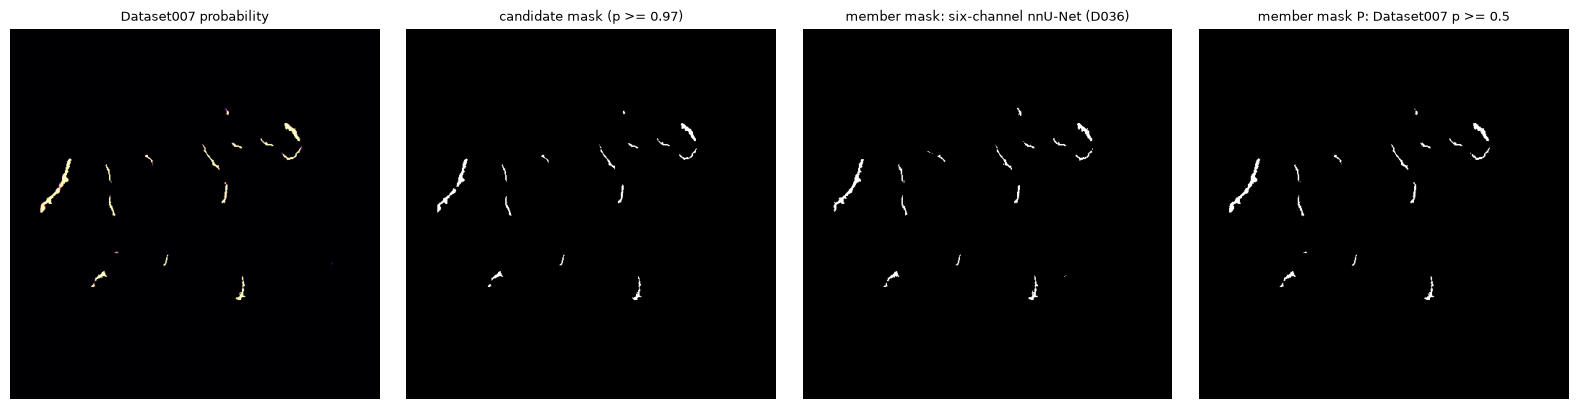

In [6]:
pr = render.test_prob(cfg, case)
from filament_seg.selector_features import member_masks
member_files = [m.test_file(case, image_id) if m.is_file else None for m in cfg.members]   # P: None (no file)
files = dict(zip([m.name for m in cfg.members], member_files))
members = member_masks(cfg.members, pr, lambda m: files[m.name])
p = candidates.base_mask(cfg.base_mask, pr, cfg.core_t)
L, n, pa, _ = candidates.label_base(p)
Ls, ns, sa, _, _ = candidates.small_components(p)
print(f"{n} candidates >= 300 px, {ns} of 100-299 px; base mask {int(p.sum())} px")
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
show(axs[0], pr, "Dataset007 probability", cmap="magma", vmin=0, vmax=1)
show(axs[1], p, "candidate mask (p >= 0.97)", cmap="gray")
show(axs[2], members[0], "member mask: six-channel nnU-Net (D036)", cmap="gray")
show(axs[3], members[1], "member mask P: Dataset007 p >= 0.5", cmap="gray")
plt.tight_layout(); plt.show()

`render.test_rows` computes every candidate's 22 features from the probability map, the two member masks and channel
0, with the code that built the 707 out-of-fold training rows. The bag's mean prediction is the expected per-record
PQ credit of each candidate; a candidate is kept when it exceeds the cut.

In [7]:
bag_file = ROOT / "weights" / "selector" / "FAST_bag.pkl"
assert weights.sha256(bag_file) == weights.manifest()["selector/FAST_bag.pkl"], "selector bag does not match the manifest"
row = render.test_rows((cfg, image_id, case, member_files))
X, area, _, timg, simg = render.design_matrix([row])
d = pickle.load(open(bag_file, "rb"))
score = render.scores(d["bag"], X)
keep = render.select(d["bag"], X, d["cut"])
print(f"features: {X.shape[1]} columns; cut = {d['cut']:.4f}; kept {int(keep.sum())} of {len(keep)} candidates, "
      f"deleted {int((~keep).sum())}")
for i in np.argsort(-area)[:12]:
    print(f"  area {int(area[i]):6d} px   score {score[i]:.3f}   {'KEEP' if keep[i] else 'drop'}")

features: 22 columns; cut = 0.2110; kept 13 of 16 candidates, deleted 3
  area   3063 px   score 0.324   KEEP
  area   2813 px   score 0.107   drop
  area   2457 px   score 0.635   KEEP
  area   1683 px   score 0.699   KEEP
  area   1301 px   score 0.498   KEEP
  area   1168 px   score 0.560   KEEP
  area   1141 px   score 0.434   KEEP
  area    997 px   score 0.369   KEEP
  area    946 px   score 0.352   KEEP
  area    696 px   score 0.619   KEEP
  area    635 px   score 0.483   KEEP
  area    538 px   score 0.384   KEEP


The kept components become 4-connected instances of at least 20 px, disjoint by construction, written as COCO-RLE
rows. Kept candidates are outlined in blue, deleted ones in red, dashed.

13 rows here, 13 in the submitted file; Dice of the two union masks 1.0000
agrees with the submitted file: True
largest deleted candidate: 2813 px, score 0.107; overlaps the submitted rows: False


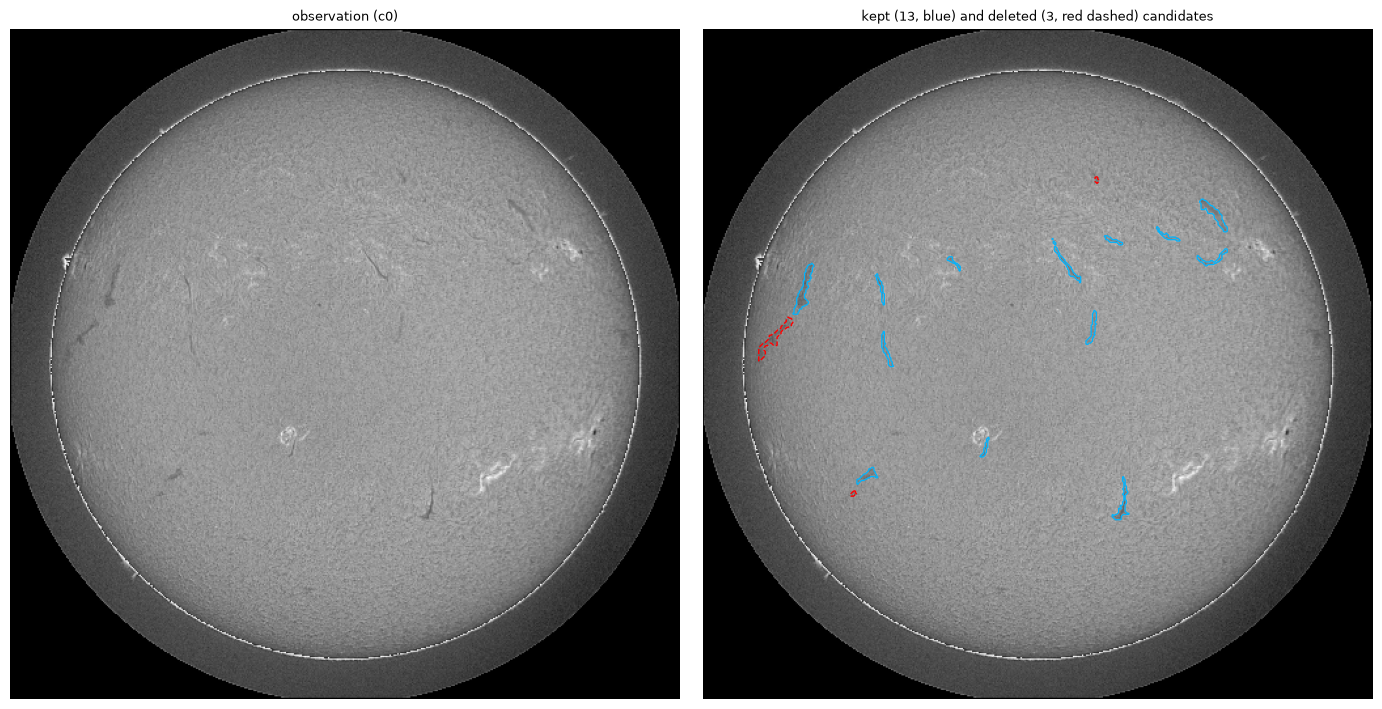

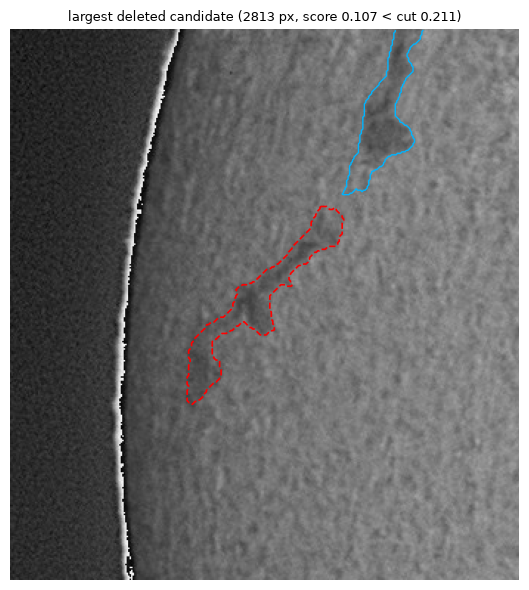

In [8]:
m = render.kept_mask(p, keep[:row["n"]], keep[row["n"]:])
rows = rle.rows_for_mask(image_id, m, cfg.min_area_csv)
shipped = [r for r in csv.reader(open(ROOT / "submissions" / "FAST.csv")) if r[0].rsplit("_", 1)[0] == image_id]

def union(rows_):
    u = np.zeros((2048, 2048), bool)
    for r in rows_:
        u |= mask_utils.decode({"size": [2048, 2048], "counts": r[1].encode()}).astype(bool)
    return u

a, b = union(rows), union(shipped)
dice = 1.0 if not (a.sum() + b.sum()) else 2 * (a & b).sum() / (a.sum() + b.sum())
print(f"{len(rows)} rows here, {len(shipped)} in the submitted file; Dice of the two union masks {dice:.4f}")
print("agrees with the submitted file:", len(rows) == len(shipped) and dice >= 0.95)
cand = np.where(L > 0, L, np.where(Ls > 0, Ls + n, 0))           # candidate j (row order) = label j + 1
big_del = max(np.flatnonzero(~keep), key=lambda j: area[j])
dmask = cand == big_del + 1
print(f"largest deleted candidate: {int(area[big_del])} px, score {score[big_del]:.3f}; "
      f"overlaps the submitted rows: {bool((dmask & b).any())}")
deleted = (cand > 0) & ~m
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
show(axs[0], ch[0], "observation (c0)", cmap="gray")
axs[1].imshow(ch[0][::4, ::4], cmap="gray")
axs[1].contour(m[::4, ::4], levels=[0.5], colors="#00b4ff", linewidths=0.9)
axs[1].contour(deleted[::4, ::4], levels=[0.5], colors="red", linewidths=1.0, linestyles="dashed")
axs[1].set_title(f"kept ({int(keep.sum())}, blue) and deleted ({int((~keep).sum())}, red dashed) candidates",
                 fontsize=9); axs[1].axis("off")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 6))                 # zoom on the largest deleted candidate
ys, xs = np.nonzero(dmask)
y0, y1, x0, x1 = max(ys.min() - 120, 0), min(ys.max() + 120, 2048), max(xs.min() - 120, 0), min(xs.max() + 120, 2048)
ax.imshow(ch[0][y0:y1, x0:x1], cmap="gray")
ax.contour(m[y0:y1, x0:x1], levels=[0.5], colors="#00b4ff", linewidths=1.0)
ax.contour(deleted[y0:y1, x0:x1], levels=[0.5], colors="red", linewidths=1.2, linestyles="dashed")
ax.set_title(f"largest deleted candidate ({int(area[big_del])} px, score {score[big_del]:.3f} < cut {d['cut']:.3f})",
             fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Evaluation

It evaluates the SHIPPED model (its out-of-fold outputs are in `eval_bundle/`; with `TRAIN = True` the retrained
models are not re-evaluated here). The test annotations are not available, so the evaluation uses the 707 training observations, each predicted by the
network fold that did not train on it (out of fold). On the 296 observations drawn by two or three annotators, one
annotator is held out in turn and the model is scored against the others with the organizers' per-record rule; the
held-out annotator, scored the same way, is the human reference. These are the numbers of the paper's Table 1.

Three CPU steps, each checking its own output against the reported values in `configs/eval/expected.json` (and
exiting non-zero on any mismatch): stage the evaluation inputs from `eval_bundle/` and the download; cross-fit the
selector on the out-of-fold rows; score against the held-out annotator.

stage evaluation inputs        rc 0    (123 s)


cross-fitted selector          rc 0    (18 s)


held-out annotator (Table 1)   rc 0  gate PASS 61.5 s  (62 s)

296 observations, 743 (observation, held-out annotator) units
                                           Dice    IoU     PQ  GT 1:0 GT 1:>=2 pred 0:1
held-out annotator                        0.616  0.517  0.340   0.178    0.032    0.178
nnHALO                                 0.673  0.591  0.444   0.170    0.035    0.155
single network (p >= 0.5, >= 400 px)      0.674  0.566  0.409   0.113    0.053    0.236


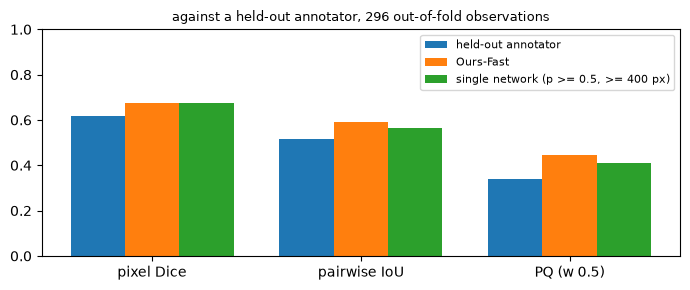

In [9]:
cpu_py = pipeline.interpreter("cpu")
env = pipeline.env()
for name, argv in (("stage evaluation inputs", ["-m", "filament_seg.evaluation.bundle", "stage", "--work", str(fp.WORK)]),
                   ("cross-fitted selector", ["scripts/eval_oof_selection.py"]),
                   ("held-out annotator (Table 1)", ["scripts/eval_heldout_annotator.py"])):
    t0 = time.time()
    r = subprocess.run([cpu_py, *argv], cwd=str(ROOT), env=env, capture_output=True, text=True)
    TIMES[f"evaluation: {name}"] = time.time() - t0
    gate = [l for l in r.stdout.splitlines() if l.startswith("gate")]
    print(f"{name:30s} rc {r.returncode}  {gate[-1] if gate else ''}  ({time.time() - t0:.0f} s)")
    assert r.returncode == 0, r.stdout[-2000:] + r.stderr[-2000:]
from filament_seg.evaluation import expected, oof_selection
seed = expected.load("heldout_annotator")["rerun_seed"]             # the bootstrap seed of the paper's intervals
S = json.load(open(oof_selection.eval_dir() / "heldout_annotator.json"))["results"][f"seed_{seed}"]
pts, dice = S["points"], S["dice"]
rowsT = [("held-out annotator", "H_A0", dice["H_image_mean"]), ("nnHALO", "FAST", dice["FAST_image_mean"]),
         ("single network (p >= 0.5, >= 400 px)", "D007", dice["D007_image_mean"])]
print(f"\n{S['n_images']} observations, {S['n_units']} (observation, held-out annotator) units")
print(f"{'':40s} {'Dice':>6s} {'IoU':>6s} {'PQ':>6s}  {'GT 1:0':>6s} {'GT 1:>=2':>8s} {'pred 0:1':>8s}")
for lab, k, dm in rowsT:
    q = pts[k]
    print(f"{lab:40s} {dm:6.3f} {q['mean_iou']:6.3f} {q['pq_w05']:6.3f}  {q['gt_1to0']:6.3f} {q['gt_1toge2']:8.3f} {q['pred_0to1']:8.3f}")
fig, ax = plt.subplots(figsize=(7, 3))
xs = np.arange(3); w = 0.26
for j, (lab, k, dm) in enumerate(rowsT):
    ax.bar(xs + (j - 1) * w, [dm, pts[k]["mean_iou"], pts[k]["pq_w05"]], w, label=lab)
ax.set_xticks(xs, ["pixel Dice", "pairwise IoU", "PQ (w 0.5)"]); ax.set_ylim(0, 1); ax.legend(fontsize=8)
ax.set_title("against a held-out annotator, 296 out-of-fold observations", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Runtime of this run

Wall-clock time of every stage that ran in this execution of the notebook (stages already on disk are not listed),
and the largest resident memory of a single child process.

In [10]:
import resource
total = 0.0
for k, v in TIMES.items():
    print(f"{k:42s} {v:8.1f} s")
    total += v
print(f"{'total':42s} {total:8.1f} s  ({total / 60:.1f} min)")
pred = sum(v for k, v in TIMES.items() if k in ("channels", "base_D007_f0", "bin_D036_f0", "selector_FAST"))
print(f"prediction of the 180 test observations (section 3): {pred:.1f} s ({pred / 60:.1f} min)")
print(f"largest child resident memory: {resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss / 2**20:.2f} GiB")

weights                                         0.3 s
training smoke test                           122.9 s
channels                                      240.1 s
base_D007_f0                                  373.6 s
bin_D036_f0                                   403.8 s
selector_FAST                                 128.4 s
evaluation: stage evaluation inputs           122.9 s
evaluation: cross-fitted selector              17.5 s
evaluation: held-out annotator (Table 1)       61.7 s
total                                        1471.2 s  (24.5 min)
prediction of the 180 test observations (section 3): 1145.9 s (19.1 min)
largest child resident memory: 6.26 GiB
